# 02 — Entrelazamiento: Bell, CHSH y GHZ

**Curso ECCI 2026 · Computación cuántica**

El notebook 01b terminó con una puerta abierta. El escéptico de las
variables ocultas todavía podía explicar el Stern-Gerlach diciendo: *"el
imán de $x$ perturba
físicamente el valor de $z$; la medición no revela, patea"*. Es incómodo,
pero
no es refutable con un solo átomo.

Acá cerramos esa puerta. La idea de Bell (1964) es poner los dos observables
**en átomos distintos y separados**, de modo que una perturbación tendría
que
viajar de uno al otro. Si se separan lo suficiente, tendría que viajar más
rápido que la luz.

Recorrido:

1. Dos qubits: producto tensorial, y qué significa que un estado **no** se
   factorice.
2. Los cuatro estados de Bell, vistos con Q-sphere y con los discos por
qubit.
3. La correlación perfecta **en toda base** — que ninguna mezcla clásica
imita.
4. **CHSH**: la desigualdad, los cuatro ángulos, y $S = 2\sqrt2$ medido.
5. **GHZ de 3 a 8 qubits**: poblaciones, oscilación de paridad, y el techo
de
   NISQ visible a simple vista.
6. Hardware real, con flags, al final.

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [1]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

try:
    import utils
    print(f"utils.py versión {utils.__version__}")
except ImportError:
    print("utils.py todavía no está disponible")

entorno local: no hay nada que instalar


utils.py versión 2026-09-19


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.quantum_info import (DensityMatrix, Pauli, Statevector, entropy,
                                 partial_trace, state_fidelity)
from qiskit.visualization import plot_state_qsphere
from qiskit_ibm_runtime.fake_provider import FakeFez

import plotly.io as pio

import utils

utils.estilo()
pio.renderers.default = "plotly_mimetype"
fez = FakeFez()
SHOTS = 8192
print("listo")

listo


## Autenticación (opcional, y en memoria)

La API key se tipea a mano y vive solo en la memoria de este kernel. Sin
correr esta celda, el notebook entero funciona en simulador.

In [3]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — el notebook corre entero en simulador")

sin autenticar — el notebook corre entero en simulador


---
# 1. Dos qubits

El espacio de estados de dos qubits es el **producto tensorial** de los de
cada uno: dimensión $2 \times 2 = 4$, con base

$$\{|00\rangle,\ |01\rangle,\ |10\rangle,\ |11\rangle\}.$$

Un estado general es

$$|\psi\rangle = \alpha|00\rangle + \beta|01\rangle + \gamma|10\rangle + \delta|11\rangle .$$

**Convención de Qiskit:** en $|q_1 q_0\rangle$ el qubit 0 va a la
**derecha**.
Así que $|01\rangle$ significa $q_1 = 0$, $q_0 = 1$.

### Separable o entrelazado

Un estado es **separable** si se puede escribir como un producto,
$|\psi\rangle = |a\rangle \otimes |b\rangle$. Ahí cada qubit tiene su propio
estado, y describir el todo es describir las partes.

Si **no** se puede, el estado está **entrelazado**. Y esto no es una
sutileza
matemática: tiene una consecuencia medible, que es la que vamos a explotar.

La cuenta rápida: $|\psi\rangle$ es separable si y solo si
$\alpha\delta - \beta\gamma = 0$. Para el estado de Bell
$|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt2$ tenemos
$\alpha = \delta = 1/\sqrt2$ y $\beta = \gamma = 0$, así que
$\alpha\delta - \beta\gamma = 1/2 \neq 0$: **no factoriza**, por más que uno
insista.

### El circuito, etapa por etapa

Dos compuertas alcanzan. Las barreras numeradas marcan dónde calculamos.

El circuito de |Φ+⟩:


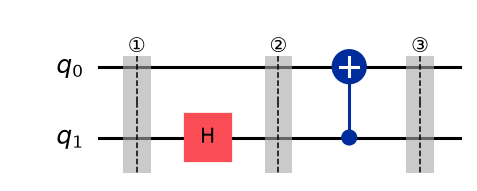

estado final: [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]


In [4]:
MARCAS = "①②③④⑤⑥⑦⑧⑨"


def marca(qc, n):
    """Barrera numerada: el punto donde el texto calcula el estado."""
    qc.barrier(label=MARCAS[n - 1])
    return qc


def bell(cual="Phi+", medir=False) -> QuantumCircuit:
    """Los cuatro estados de Bell salen del mismo circuito, cambiando la
    preparación inicial:
        |Phi+> = (|00>+|11>)/√2      |Phi-> = (|00>-|11>)/√2
        |Psi+> = (|01>+|10>)/√2      |Psi-> = (|01>-|10>)/√2
    """
    qc = QuantumCircuit(2, 2) if medir else QuantumCircuit(2)
    if cual in ("Psi+", "Psi-"):
        qc.x(0)
    if cual in ("Phi-", "Psi-"):
        qc.x(1)
    marca(qc, 1)
    qc.h(1)
    marca(qc, 2)
    qc.cx(1, 0)
    marca(qc, 3)
    if medir:
        qc.measure([0, 1], [0, 1])
        marca(qc, 4)
    return qc


phi_mas = bell("Phi+")
print("El circuito de |Φ+⟩:")
display(phi_mas.draw("mpl", style="iqp"))
print("estado final:", np.round(Statevector(phi_mas).data, 4))

### La cuenta

**①** Estado inicial: $|\psi_1\rangle = |00\rangle$. Separable, aburrido,
cada
qubit en su polo norte.

**②** Dado que se aplica $H$ sobre el qubit 1:

$$|\psi_2\rangle = (H \otimes I)\,|00\rangle
  = \frac{|00\rangle + |10\rangle}{\sqrt2}
  = \left(\frac{|0\rangle + |1\rangle}{\sqrt2}\right)_{q_1} \otimes
    |0\rangle_{q_0}.$$

**Todavía factoriza**: es $|+\rangle \otimes |0\rangle$. Hay
superposición, pero no hay entrelazamiento. Son cosas distintas, y este es
el
momento exacto en que se ve la diferencia.

**③** Dado que se aplica CNOT con control en $q_1$ y blanco en $q_0$ — que
lleva $|00\rangle \to |00\rangle$ y $|10\rangle \to |11\rangle$:

$$|\psi_3\rangle = \frac{|00\rangle + |11\rangle}{\sqrt2} = |\Phi^+\rangle .$$

Y esto ya **no** factoriza. La CNOT no hizo nada espectacular: copió una
superposición que ya estaba. Lo espectacular es que al hacerlo, el estado
dejó
de tener partes.

**④** Dado que se mide en la base computacional:
$P(00) = P(11) = 1/2$, $P(01) = P(10) = 0$. Nunca discrepan.

---
## 1.1 Tres maneras de mirar el mismo estado

### La Q-sphere

La esfera de Bloch sirve para **un** qubit. Con dos o más no alcanza, porque
el entrelazamiento es información que no vive en ningún qubit por separado.
La **Q-sphere** muestra el estado global de otra manera:

| elemento | qué codifica |
|---|---|
| cada punto | uno de los $2^n$ estados de la base computacional |
| **latitud** | el peso de Hamming: $\|0\dots0\rangle$ en el polo norte, $\|1\dots1\rangle$ en el sur |
| **tamaño del punto** | $\|$amplitud$\|^2$, la probabilidad |
| **color** | la **fase** de esa amplitud |

Para $|\Phi^+\rangle$ vamos a ver exactamente dos puntos, en los dos polos,
del
mismo tamaño y del mismo color: misma probabilidad, misma fase. Para
$|\Phi^-\rangle$, dos puntos iguales pero de **colores opuestos**: ahí está
el
signo menos, que los histogramas de conteos no pueden mostrar porque la
probabilidad es idéntica.

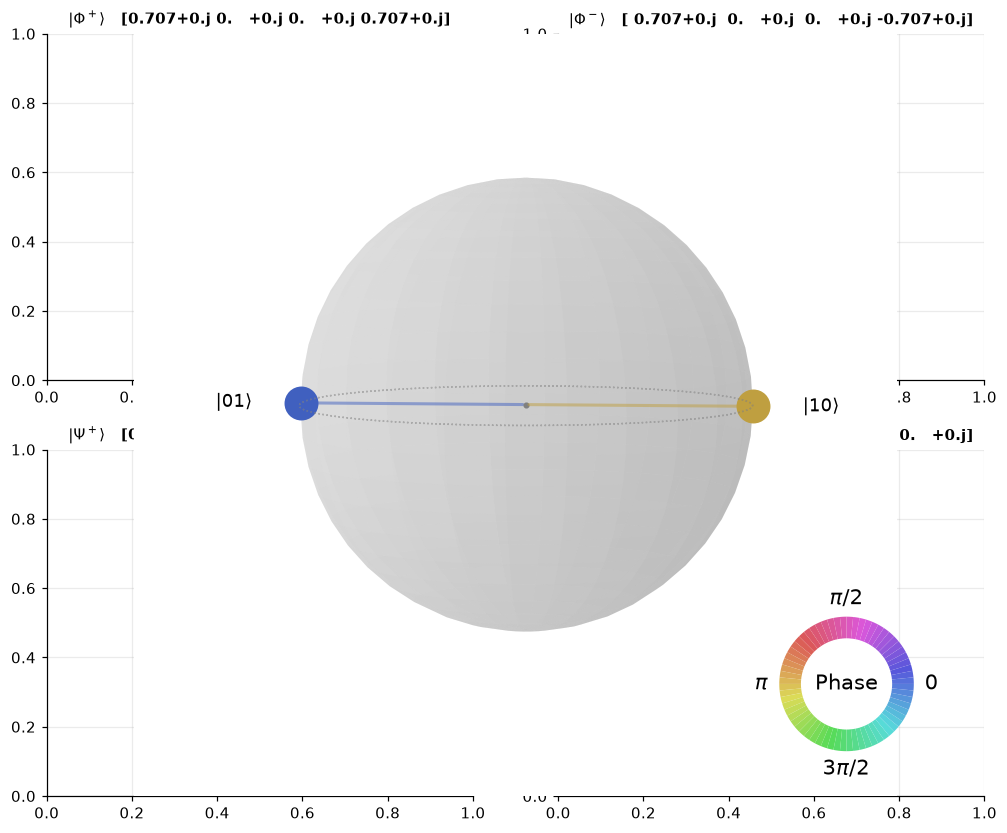

In [5]:
fig = plt.figure(figsize=(11, 9))
for i, cual in enumerate(["Phi+", "Phi-", "Psi+", "Psi-"]):
    sv = Statevector(bell(cual))
    ax = fig.add_subplot(2, 2, i + 1)
    qs = plot_state_qsphere(sv, ax=ax, show_state_labels=True)
    simbolo = {"Phi+": r"$|\Phi^+\rangle$", "Phi-": r"$|\Phi^-\rangle$",
               "Psi+": r"$|\Psi^+\rangle$", "Psi-": r"$|\Psi^-\rangle$"}[cual]
    ax.set_title(f"{simbolo}   {np.round(sv.data, 3)}", fontsize=10)
plt.show()

**Los cuatro estados de Bell son ortogonales entre sí** y forman una base
del
espacio de dos qubits: la base de Bell. Cualquier estado de dos qubits es
una
combinación de estos cuatro. Eso va a importar mucho en el notebook 03,
porque
la teleportación es, literalmente, medir en esta base.

Miremos qué separa a $|\Phi^+\rangle$ de $|\Phi^-\rangle$ en la Q-sphere:
**solo
el color**. Los tamaños son idénticos. Si se mide en la base computacional los
dos dan 50 % `00` y 50 % `11`, indistinguibles. La diferencia es la fase
relativa, y para verla hay que medir en otra base — la misma lección del
horno del 01b, ahora con dos qubits.

### Los discos por qubit

Y acá está el hecho central del notebook, en una figura.

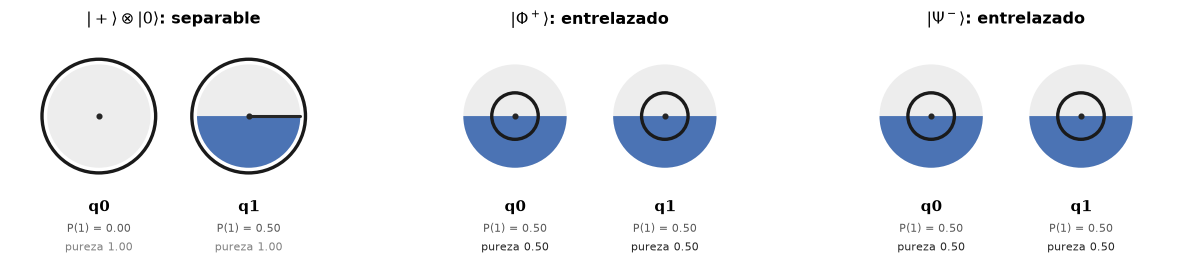

separable |+>|0>     pureza global = 1.000   pureza de q0 = 1.000   entropía de entrelazamiento = 0.000 bits
Bell |Φ+>            pureza global = 1.000   pureza de q0 = 0.500   entropía de entrelazamiento = 1.000 bits


In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(11.5, 2.6))
qc_sep = QuantumCircuit(2); qc_sep.h(1)
utils.discos_qubits(Statevector(qc_sep), ax=ejes[0],
                    titulo="$|+\\rangle \\otimes |0\\rangle$: separable")
utils.discos_qubits(Statevector(bell("Phi+")), ax=ejes[1],
                    titulo="$|\\Phi^+\\rangle$: entrelazado")
utils.discos_qubits(Statevector(bell("Psi-")), ax=ejes[2],
                    titulo="$|\\Psi^-\\rangle$: entrelazado")
utils.layout(fig)
plt.show()

for nombre, sv in [("separable |+>|0>", Statevector(qc_sep)),
                   ("Bell |Φ+>", Statevector(bell("Phi+")))]:
    rho = DensityMatrix(sv)
    r0 = partial_trace(rho, [1])
    print(f"{nombre:<20} pureza global = "
          f"{np.real(np.trace(rho.data @ rho.data)):.3f}   "
          f"pureza de q0 = {np.real(np.trace(r0.data @ r0.data)):.3f}   "
          f"entropía de entrelazamiento = {entropy(r0):.3f} bits")

El estado separable tiene los dos discos con **borde sólido**: cada qubit
está puro, cada uno tiene su propio estado, y describir el par es describir
las partes.

Los dos estados de Bell tienen los dos discos **punteados y sin aguja**:
pureza $1/2$, la mezcla máxima de un qubit. Y sin embargo el estado global
es
**puro**, pureza 1. Eso es una contradicción para la intuición clásica,
donde
el todo no puede saberse mejor que las partes.

La **entropía de entrelazamiento** lo cuantifica: es la entropía de von
Neumann del estado reducido, $S = -\mathrm{Tr}(\rho_0 \log_2 \rho_0)$. Vale
$0$ para el separable y **1 bit** para Bell. Ese bit es la información que
existe en la correlación y en ninguna otra parte.

Schrödinger lo dijo mejor que nadie, en 1935:

> *"El conocimiento máximo de un todo no incluye necesariamente el
> conocimiento máximo de sus partes."*

### El recorrido, etapa por etapa

El deslizador muestra dónde nace el entrelazamiento. Miremos la pureza de cada
disco: en ① y ② los dos bordes están sólidos, en ③ los dos se puntean **al
mismo tiempo**. La CNOT no le hizo nada a un qubit: convirtió información
local en correlación.

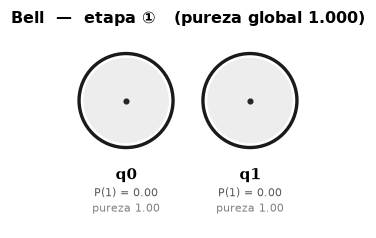

① |00>: separable, los dos puros


SelectionSlider(continuous_update=False, description='etapa', layout=Layout(width='520px'), options=('①', '②',…

Output()

Output()

In [7]:
utils.explorador_de_etapas(
    bell("Phi+", medir=True), titulo="Bell", etiquetas_qubits=["q0", "q1"],
    texto={"①": "① |00>: separable, los dos puros",
           "②": "② H sobre q1: superposición, PERO todavía separable (|+>|0>)",
           "③": "③ CNOT: acá nace el entrelazamiento, los dos se mezclan a la vez",
           "④": "④ tras medir: la correlación se volvió clásica (00 o 11)"})

---
# 2. La correlación que ninguna moneda imita

Acá está el experimento que hay que entender antes de CHSH.

Medimos los dos qubits de $|\Phi^+\rangle$ **en la misma base** y
comparamos.
En la base $Z$ el resultado es obvio: siempre coinciden, `00` o `11`.

Pero eso tiene una explicación clásica trivial: una máquina que tira una
moneda y manda dos papelitos iguales, "0 y 0" o "1 y 1". Correlación
perfecta,
cero misterio.

La prueba está en medir en **otra** base. Reescribimos $|\Phi^+\rangle$ en
la
base de $X$:

$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt2}
                 = \frac{|{+}{+}\rangle + |{-}{-}\rangle}{\sqrt2}.$$

**La misma forma.** También coinciden siempre en $X$. Y en $Y$ anticoinciden
siempre. Eso los papelitos no lo pueden hacer: si la máquina escribió "0 y
0"
en la base $Z$, al medir en $X$ cada papelito tendría que dar 50/50
**independiente** del otro, porque el papelito no sabe en qué base lo van a
leer.

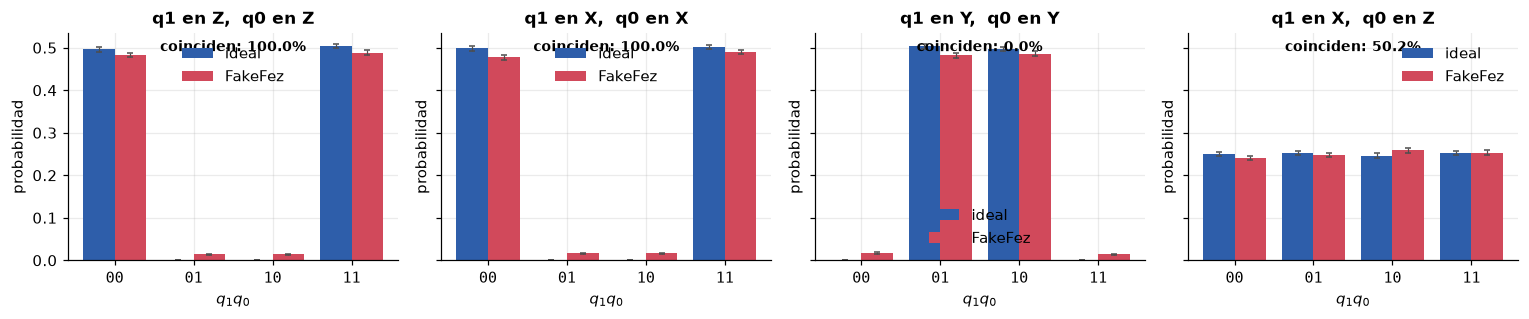

base (Z,Z):  correlación E = +1.0000
base (X,X):  correlación E = +1.0000
base (Y,Y):  correlación E = -1.0000
base (Z,X):  correlación E = +0.0032


In [8]:
def bell_medido(base_a="Z", base_b="Z", cual="Phi+", angulos=None):
    """|Φ+⟩ medido con cada qubit en la base que se pida.
    Si se pasan `angulos` (θa, θb), mide el observable cos θ·Z + sin θ·X."""
    qc = bell(cual)
    qc.add_register(ClassicalRegister(2, "c"))
    if angulos is not None:
        qc.ry(-angulos[0], 0)
        qc.ry(-angulos[1], 1)
    else:
        for q, base in ((0, base_a), (1, base_b)):
            if base == "X":
                qc.h(q)
            elif base == "Y":
                qc.sdg(q); qc.h(q)
    marca(qc, 4)
    qc.measure([0, 1], [0, 1])
    return qc


bases = [("Z", "Z"), ("X", "X"), ("Y", "Y"), ("Z", "X")]
circuitos_bases = [bell_medido(a, b) for a, b in bases]
counts_bases = utils.correr_ideal(circuitos_bases, shots=SHOTS)
counts_bases_ruido = utils.correr_ruidoso(circuitos_bases, backend_falso=fez, shots=SHOTS)

fig, ejes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, (a, b), ci, cr in zip(ejes, bases, counts_bases, counts_bases_ruido):
    utils.comparar_conteos({"ideal": ci, "FakeFez": cr},
                           claves=utils.claves_completas(2), ax=ax,
                           titulo=f"q1 en {b},  q0 en {a}")
    ax.set_xlabel("$q_1 q_0$")
    corr = sum(v for k, v in ci.items() if k[0] == k[1]) / SHOTS
    ax.text(0.5, 0.92, f"coinciden: {corr:.1%}", transform=ax.transAxes,
            ha="center", fontsize=9, fontweight="bold")
utils.layout(fig)
plt.show()

for (a, b), c in zip(bases, counts_bases):
    e = sum(v * (1 if k[0] == k[1] else -1) for k, v in c.items()) / SHOTS
    print(f"base ({a},{b}):  correlación E = {e:+.4f}")

**$ZZ$ y $XX$ dan correlación $+1$. $YY$ da $-1$. $ZX$ da $0$.**

Las tres primeras son el problema para cualquier explicación con papelitos.
Un
modelo de variables ocultas tendría que mandar, en cada tirada, una
instrucción que ya diga qué contestar en $Z$, en $X$ **y** en $Y$ — y que
además garantice coincidencia en las dos primeras y discrepancia en la
tercera, para *todas* las tiradas.

Se puede fabricar un modelo así para estas tres bases. Lo que Bell demostró
es
que si además se pide ángulos **intermedios**, ningún modelo de ese tipo puede
reproducir las predicciones cuánticas. Eso es lo que sigue.

### Para probar: la correlación es condicional

El explorador de abajo tiene los dos qubits como filtros. Fijar `q0 = ↑` y
miremos qué queda de `q1`: sale una sola barra. Después sacar el filtro y se vuelve
a ver 50/50. **Medir un qubit determina el otro**, y eso vale en $Z$ y en
$X$.

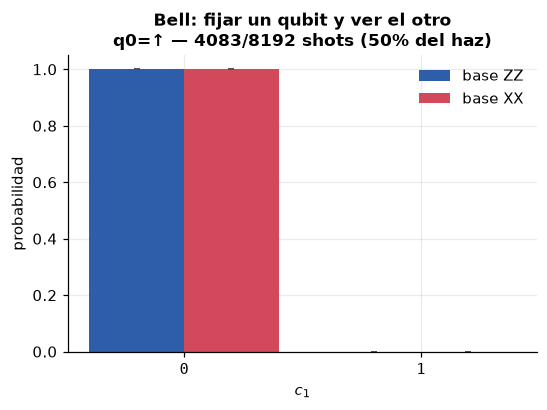

Output()

Output()

In [9]:
utils.postseleccion_interactiva(
    {"base ZZ": counts_bases[0], "base XX": counts_bases[1]},
    nombres={0: "q0", 1: "q1"},
    titulo="Bell: fijar un qubit y ver el otro",
    inicial={0: "0"})

---
# 3. CHSH: la desigualdad que separa los mundos

## 3.1 El argumento clásico

Alice y Bob reciben cada uno un qubit del par, y se van lejos. Cada uno
elige
**una de dos** mediciones posibles: Alice mide $A_0$ o $A_1$, Bob mide $B_0$
o
$B_1$. Cada medición devuelve $\pm 1$.

Un **realista local** sostiene dos cosas:

- **Realismo:** los cuatro valores $a_0, a_1, b_0, b_1$ ya existen antes de
  medir, aunque solo lleguemos a ver dos de ellos por tirada.
- **Localidad:** lo que elige Alice no afecta al resultado de Bob.

Si eso es cierto, considerá esta combinación, para **una** tirada:

$$s = a_0 b_0 + a_0 b_1 + a_1 b_0 - a_1 b_1
    = a_0(b_0 + b_1) + a_1(b_0 - b_1).$$

Como $b_0, b_1 \in \{-1, +1\}$, o bien $b_0 + b_1 = 0$ (y entonces
$b_0 - b_1 = \pm2$), o bien $b_0 - b_1 = 0$ (y $b_0 + b_1 = \pm2$).
**Siempre
uno de los dos paréntesis se anula.** Así que $s = \pm 2$ en cada tirada, y
promediando sobre muchas:

$$\boxed{\;|S| = |E(A_0,B_0) + E(A_0,B_1) + E(A_1,B_0) - E(A_1,B_1)| \le 2\;}$$

Esa es la desigualdad CHSH. **La derivación no usa física**: solo que los
cuatro
valores existen a la vez y que valen $\pm 1$. Cualquier teoría realista
local
la cumple, sea cual sea el mecanismo.

## 3.2 La predicción cuántica

La mecánica cuántica no le hace caso. Para $|\Phi^+\rangle$, midiendo el
observable $M(\theta) = \cos\theta\, Z + \sin\theta\, X$ en cada lado:

$$E(\theta_a, \theta_b) = \langle M(\theta_a) \otimes M(\theta_b)\rangle
  = \cos(\theta_a - \theta_b).$$

Con los ángulos
$\theta_{a_0} = 0$, $\theta_{a_1} = \pi/2$,
$\theta_{b_0} = \pi/4$, $\theta_{b_1} = -\pi/4$:

$$S = \cos(-\tfrac{\pi}{4}) + \cos(\tfrac{\pi}{4})
    + \cos(\tfrac{\pi}{4}) - \cos(\tfrac{3\pi}{4})
    = 4 \cdot \frac{\sqrt2}{2} = 2\sqrt2 \approx 2.828 .$$

**Los tres primeros términos empujan para arriba y el cuarto, que se resta,
es
negativo y también empuja para arriba.** Ese es todo el truco: elegir
ángulos donde las cuatro correlaciones suman en el mismo sentido. Un modelo
clásico no puede lograr eso con las cuatro a la vez, porque las cuatro
comparten los mismos valores ocultos.

### Cómo se mide $M(\theta)$

Qiskit mide en $Z$. Y como $M(\theta) = R_y(\theta)\, Z\,
R_y(\theta)^\dagger$,
para medir $M(\theta)$ alcanza con aplicar $R_y(-\theta)$ y medir en $Z$.
Una
línea por qubit.

Uno de los cuatro circuitos de CHSH (A0, B1):


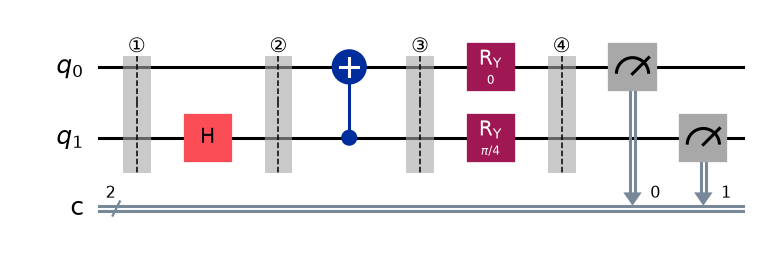

In [10]:
ANGULOS_CHSH = {"a0": 0.0, "a1": np.pi / 2, "b0": np.pi / 4, "b1": -np.pi / 4}
COMBINACIONES = [("a0", "b0", +1), ("a0", "b1", +1),
                 ("a1", "b0", +1), ("a1", "b1", -1)]


def circuitos_chsh(angulos=ANGULOS_CHSH):
    """Los 4 circuitos de CHSH. Van todos juntos en un solo job."""
    return [bell_medido(angulos=(angulos[a], angulos[b]))
            for a, b, _ in COMBINACIONES]


def correlacion(counts) -> float:
    """E = P(iguales) - P(distintos), sobre resultados ±1."""
    n = sum(counts.values())
    return sum(v * (1 if k[0] == k[1] else -1) for k, v in counts.items()) / n


def valor_S(lista_counts, combinaciones=COMBINACIONES):
    return sum(signo * correlacion(c) for c, (_, _, signo) in
               zip(lista_counts, combinaciones))


chsh = circuitos_chsh()
print("Uno de los cuatro circuitos de CHSH (A0, B1):")
display(chsh[1].draw("mpl", style="iqp"))

### La cuenta, etapa por etapa (el circuito de $E(a_0, b_1)$)

**①** $|\psi_1\rangle = |00\rangle$. Nada todavía.

**②** Dado que se aplica $H$ al qubit 1:
$|\psi_2\rangle = |+\rangle \otimes |0\rangle$. Superposición, pero
**separable**: los dos qubits todavía tienen estado propio.

**③** Dado que se aplica la CNOT:
$$|\psi_3\rangle = \frac{|00\rangle + |11\rangle}{\sqrt2} = |\Phi^+\rangle .$$
Acá Alice y Bob se separan y se llevan un qubit cada uno. **Todo lo que
sigue
es local**: cada uno toca solo el suyo.

**④** Dado que cada uno aplica su rotación de base antes de medir. Alice
quiere
medir $M(\theta_a) = \cos\theta_a Z + \sin\theta_a X$, y como
$M(\theta) = R_y(\theta)\,Z\,R_y(\theta)^\dagger$, le alcanza con aplicar
$R_y(-\theta_a)$ y medir en $Z$. Bob hace lo mismo con $\theta_b$.

Después de las dos rotaciones, medir $Z \otimes Z$ **es** medir
$M(\theta_a) \otimes M(\theta_b)$ sobre el estado original.

### Y de ahí sale el coseno

La correlación es el valor de expectación de ese producto sobre
$|\Phi^+\rangle$. Desarrollando el producto de las dos Paulis rotadas:

$$E = \cos\theta_a\cos\theta_b \langle ZZ\rangle
    + \cos\theta_a\sin\theta_b \langle ZX\rangle
    + \sin\theta_a\cos\theta_b \langle XZ\rangle
    + \sin\theta_a\sin\theta_b \langle XX\rangle .$$

Para $|\Phi^+\rangle$ esos cuatro valores son conocidos y muy simples:
$\langle ZZ\rangle = 1$, $\langle XX\rangle = 1$, y los cruzados
$\langle ZX\rangle = \langle XZ\rangle = 0$. Quedan dos términos:

$$E(\theta_a,\theta_b) = \cos\theta_a\cos\theta_b + \sin\theta_a\sin\theta_b
  = \cos(\theta_a - \theta_b).$$

**La correlación depende solo del ángulo relativo.** Ese es el resultado que
vale toda la sección: los dos experimentadores pueden estar donde quieran y
elegir lo que quieran, que lo único que importa es cuánto difieren sus
ángulos. Y es la función que, evaluada en los cuatro ángulos de CHSH, da
$2\sqrt2$ en vez de quedarse en 2.

In [11]:
c_chsh_ideal = utils.correr_ideal(chsh, shots=SHOTS)
c_chsh_ruido = utils.correr_ruidoso(chsh, backend_falso=fez, shots=SHOTS)

S_ideal, S_ruido = valor_S(c_chsh_ideal), valor_S(c_chsh_ruido)
print(f"\n{'combinación':<14} {'E ideal':>9} {'E teoría':>9} {'E FakeFez':>10}")
for (a, b, signo), ci, cr in zip(COMBINACIONES, c_chsh_ideal, c_chsh_ruido):
    teo = np.cos(ANGULOS_CHSH[a] - ANGULOS_CHSH[b])
    print(f"{('-' if signo < 0 else '+')} E({a},{b}){'':<4} "
          f"{correlacion(ci):>+9.4f} {teo:>+9.4f} {correlacion(cr):>+10.4f}")
print(f"\nS ideal   = {S_ideal:.4f}")
print(f"S FakeFez = {S_ruido:.4f}")
print(f"S teórico = {2 * np.sqrt(2):.4f}   ·   límite clásico = 2")


combinación      E ideal  E teoría  E FakeFez
+ E(a0,b0)       +0.7065   +0.7071    +0.6621
+ E(a0,b1)       +0.7087   +0.7071    +0.6489
+ E(a1,b0)       +0.6995   +0.7071    +0.6631
- E(a1,b1)       -0.7090   -0.7071    -0.6604

S ideal   = 2.8237
S FakeFez = 2.6345
S teórico = 2.8284   ·   límite clásico = 2


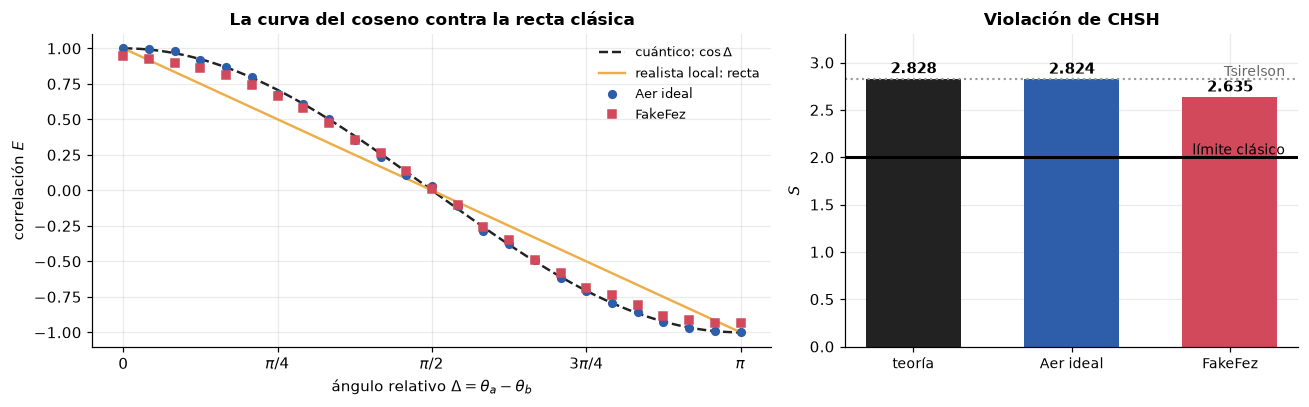

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8),
                               gridspec_kw={"width_ratios": [1.5, 1]})

# (a) la curva de correlación contra el modelo clásico que mejor la imita
deltas = np.linspace(0, np.pi, 25)
circ_barrido = [bell_medido(angulos=(0.0, d)) for d in deltas]
c_barrido = utils.correr_ideal(circ_barrido, shots=2048)
c_barrido_r = utils.correr_ruidoso(circ_barrido, backend_falso=fez, shots=2048)
E_barrido = [correlacion(c) for c in c_barrido]
E_barrido_r = [correlacion(c) for c in c_barrido_r]

d_fino = np.linspace(0, np.pi, 300)
ax1.plot(d_fino, np.cos(d_fino), color=utils.COLOR_TEORIA, ls="--", lw=1.6,
         label=r"cuántico: $\cos\Delta$")
ax1.plot(d_fino, 1 - 2 * d_fino / np.pi, color=utils.PALETA[3], lw=1.6,
         label="realista local: recta")
ax1.plot(deltas, E_barrido, "o", ms=5, color=utils.COLOR_IDEAL, label="Aer ideal")
ax1.plot(deltas, E_barrido_r, "s", ms=5, color=utils.COLOR_RUIDO, label="FakeFez")
ax1.set_xlabel(r"ángulo relativo $\Delta = \theta_a - \theta_b$")
ax1.set_ylabel("correlación $E$")
ax1.set_xticks(np.linspace(0, np.pi, 5))
ax1.set_xticklabels(["0", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$"])
ax1.set_title("La curva del coseno contra la recta clásica")
ax1.legend(fontsize=8.5)

# (b) el valor de S
ax2.bar([0, 1, 2], [2 * np.sqrt(2), S_ideal, S_ruido],
        color=[utils.COLOR_TEORIA, utils.COLOR_IDEAL, utils.COLOR_RUIDO], width=0.6)
ax2.axhline(2, color="k", lw=2)
ax2.text(2.35, 2.03, "límite clásico", fontsize=9, ha="right")
ax2.axhline(2 * np.sqrt(2), color="0.6", ls=":", lw=1.4)
ax2.text(2.35, 2 * np.sqrt(2) + 0.03, "Tsirelson", fontsize=9, ha="right", color="0.4")
ax2.set_xticks([0, 1, 2])
ax2.set_xticklabels(["teoría", "Aer ideal", "FakeFez"], fontsize=9)
ax2.set_ylim(0, 3.3)
ax2.set_ylabel("$S$")
for i, v in enumerate([2 * np.sqrt(2), S_ideal, S_ruido]):
    ax2.text(i, v + 0.06, f"{v:.3f}", ha="center", fontweight="bold")
ax2.set_title("Violación de CHSH")
utils.layout(fig)
plt.show()

**El panel de la izquierda es la figura de la clase.** La curva cuántica es
$\cos\Delta$; la mejor imitación realista local posible es la **recta**
$1 - 2\Delta/\pi$. Coinciden exactamente en $\Delta = 0$, $\pi/2$ y $\pi$
—los
tres casos "obvios" de la sección 2— y se separan en el medio. El máximo
despegue está cerca de $\Delta = \pi/4$, que es justo el ángulo que usa
CHSH.

Por eso las tres bases de la sección 2 no alcanzaban como prueba: son los
tres
puntos donde las dos teorías dicen lo mismo. Bell encontró dónde mirar.

**El panel derecho:** el simulador da $2\sqrt2 = 2.828$, el máximo que
permite
la mecánica cuántica (el **límite de Tsirelson**). Con ruido de FakeFez
baja,
pero sigue **arriba de 2**. Ese "sigue arriba de 2" es el experimento.

### Qué se descarta exactamente

Acá hay que ser preciso, porque es fácil exagerar:

- Lo que se refuta es la conjunción **realismo + localidad**. Uno puede quedarse
  con una, no con las dos.
- **No** se puede mandar información más rápido que la luz. Bob ve 50/50
haga
  lo que haga Alice; la correlación solo aparece al comparar las listas, y
    esa
  comparación viaja por un canal clásico.
- Este montaje no cierra las *escapatorias* experimentales (localidad,
  detección): los dos qubits están a micrones, en el mismo chip. Los
  experimentos "libres de escapatorias" de 2015 sí las cerraron, y dieron lo
  mismo.

### Jugá con los ángulos

In [13]:
def explorar_chsh(theta_b0_grados=45.0):
    """S en función del ángulo de Bob. El óptimo está en 45°."""
    b0 = np.radians(theta_b0_grados)
    ang = {"a0": 0.0, "a1": np.pi / 2, "b0": b0, "b1": -b0}
    S_teo = sum(signo * np.cos(ang[a] - ang[b]) for a, b, signo in COMBINACIONES)
    S_sim = valor_S(utils.correr_ideal(circuitos_chsh(ang), shots=2048))

    grados = np.linspace(0, 90, 181)
    curva = [sum(s * np.cos({"a0": 0.0, "a1": np.pi / 2,
                             "b0": np.radians(g), "b1": -np.radians(g)}[a]
                            - {"a0": 0.0, "a1": np.pi / 2,
                               "b0": np.radians(g), "b1": -np.radians(g)}[b])
                 for a, b, s in COMBINACIONES) for g in grados]
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.plot(grados, curva, color=utils.COLOR_TEORIA, lw=1.8, label="$S$ teórico")
    ax.axhline(2, color="k", lw=1.8, label="límite clásico")
    ax.axhline(2 * np.sqrt(2), color="0.6", ls=":", lw=1.3, label="Tsirelson")
    ax.plot([theta_b0_grados], [S_sim], "o", ms=10, color=utils.COLOR_RUIDO,
            label=f"simulado: S = {S_sim:.3f}")
    ax.fill_between(grados, 0, 2, color="0.9")
    ax.text(3, 1.0, "zona explicable\ncon variables ocultas locales", fontsize=9,
            color="0.35")
    ax.set_xlabel(r"$\theta_{b_0}$ [grados]   (con $\theta_{b_1} = -\theta_{b_0}$)")
    ax.set_ylabel("$S$")
    ax.set_ylim(0, 3.2)
    ax.set_title(f"S($\\theta$) — teórico {S_teo:.3f}, simulado {S_sim:.3f}")
    ax.legend(fontsize=8.5, loc="lower right")
    plt.show()


utils.deslizador(explorar_chsh, theta_b0_grados=(0.0, 90.0, 2.5))

interactive(children=(FloatSlider(value=45.0, description='theta_b0_grados', max=90.0, step=2.5), Output()), _…

interactive(children=(FloatSlider(value=45.0, description='theta_b0_grados', max=90.0, step=2.5), Output()), _…

Movelo y miremos dos cosas: que en $0°$ y en $90°$ el valor cae **dentro** de
la
zona clásica, y que el máximo está exactamente en $45°$. La violación no es
automática: hay que elegir bien dónde mirar.

---
# 4. GHZ: subiendo de a un qubit

Con dos qubits la violación es del 41 % sobre el límite clásico. Con tres
aparece algo más fuerte: el argumento **GHZ** (Greenberger-Horne-Zeilinger),
que refuta el realismo local **sin estadística**, con una sola tirada,
porque
la predicción cuántica y la clásica son opuestas en vez de "distintas en
promedio".

El estado es

$$|GHZ_n\rangle = \frac{|00\cdots0\rangle + |11\cdots1\rangle}{\sqrt2},$$

y se construye con una $H$ y una cadena de CNOT. Acá vamos a usarlo para otra
cosa
además: como **medida del ruido de NISQ**. Es el circuito más sencillo cuya
dificultad crece con $n$, así que sirve para ver dónde se cae el hardware.

### Dos formas de armarlo, y no dan lo mismo en el chip

n=4: cadena profundidad  4  ·  árbol profundidad  3   ·  ¿mismo estado? True
n=8: cadena profundidad  8  ·  árbol profundidad  4   ·  ¿mismo estado? True


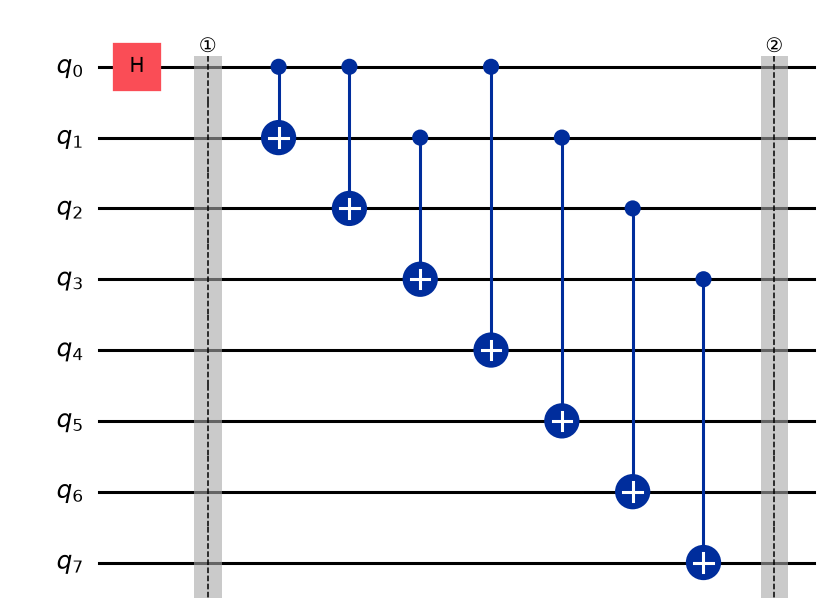

In [14]:
def ghz_cadena(n: int, medir=True) -> QuantumCircuit:
    """H + CNOTs en cadena. Profundidad n-1: cada CNOT espera a la anterior."""
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)
    qc.h(0)
    marca(qc, 1)
    for k in range(n - 1):
        qc.cx(k, k + 1)
    marca(qc, 2)
    if medir:
        qc.measure(range(n), range(n))
    return qc


def ghz_arbol(n: int, medir=True) -> QuantumCircuit:
    """H + CNOTs en árbol: cada qubit ya entrelazado copia a uno nuevo, así que
    en cada paso se duplica la cantidad. Profundidad ceil(log2 n)."""
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)
    qc.h(0)
    marca(qc, 1)
    paso = 1
    while paso < n:
        for k in range(0, min(paso, n - paso)):
            qc.cx(k, k + paso)
        paso *= 2
    marca(qc, 2)
    if medir:
        qc.measure(range(n), range(n))
    return qc


for n in (4, 8):
    a, b = ghz_cadena(n, medir=False), ghz_arbol(n, medir=False)
    ok = np.isclose(abs(Statevector(a).inner(Statevector(b))), 1.0)
    print(f"n={n}: cadena profundidad {a.depth():2}  ·  árbol profundidad {b.depth():2}"
          f"   ·  ¿mismo estado? {ok}")

display(ghz_arbol(8, medir=False).draw("mpl", style="iqp", fold=-1))

**Los dos circuitos preparan el mismo estado exacto**, pero el árbol tiene
profundidad $\lceil \log_2 n \rceil$ contra $n-1$ de la cadena. Para $n =
8$:
3 contra 7. Como el ruido se acumula con la profundidad, en hardware el
árbol
gana — aunque en el simulador ideal sean indistinguibles.

(Advertencia: en el chip real el transpilador tiene que insertar SWAPs si los qubits
no son vecinos, y eso puede anular la ventaja. Lo comparamos con FakeFez,
que
trae el coupling map real.)

### Poblaciones: la parte fácil

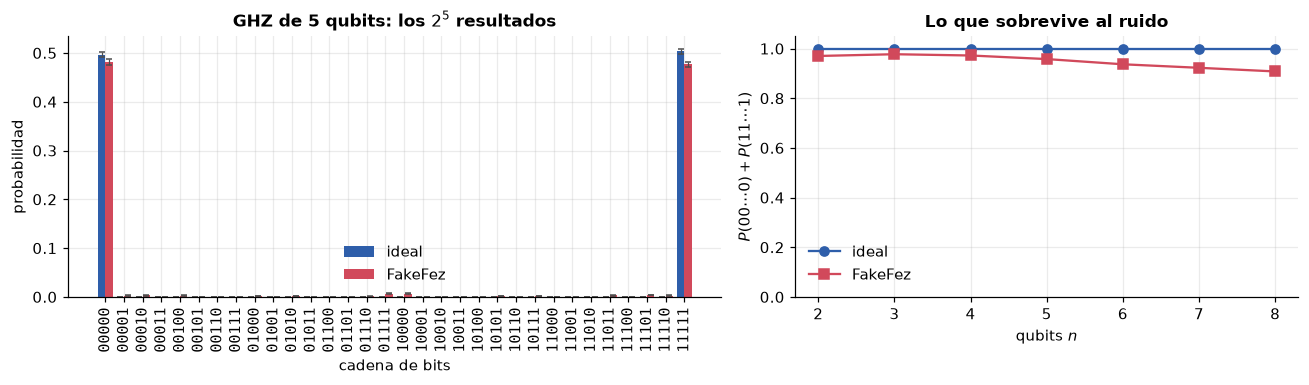

n=2:  ideal 1.000   FakeFez 0.970
n=3:  ideal 1.000   FakeFez 0.977
n=4:  ideal 1.000   FakeFez 0.972
n=5:  ideal 1.000   FakeFez 0.958
n=6:  ideal 1.000   FakeFez 0.937
n=7:  ideal 1.000   FakeFez 0.923
n=8:  ideal 1.000   FakeFez 0.908


In [15]:
NS = [2, 3, 4, 5, 6, 7, 8]
counts_ghz_ideal, counts_ghz_ruido = {}, {}
for n in NS:
    counts_ghz_ideal[n] = utils.correr_ideal(ghz_arbol(n), shots=SHOTS)
    counts_ghz_ruido[n] = utils.correr_ruidoso(ghz_arbol(n), backend_falso=fez,
                                               shots=SHOTS)


def peso_ghz(counts, n):
    """Fracción de shots en los dos estados que deberían ser los únicos."""
    total = sum(counts.values())
    return (counts.get("0" * n, 0) + counts.get("1" * n, 0)) / total


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6),
                               gridspec_kw={"width_ratios": [1.3, 1]})
n_demo = 5
utils.comparar_conteos({"ideal": counts_ghz_ideal[n_demo],
                        "FakeFez": counts_ghz_ruido[n_demo]},
                       claves=utils.claves_completas(n_demo), ax=ax1,
                       titulo=f"GHZ de {n_demo} qubits: los $2^{n_demo}$ resultados")
ax1.set_xlabel("cadena de bits")

pesos_i = [peso_ghz(counts_ghz_ideal[n], n) for n in NS]
pesos_r = [peso_ghz(counts_ghz_ruido[n], n) for n in NS]
ax2.plot(NS, pesos_i, "o-", color=utils.COLOR_IDEAL, label="ideal")
ax2.plot(NS, pesos_r, "s-", color=utils.COLOR_RUIDO, label="FakeFez")
ax2.set_xlabel("qubits $n$")
ax2.set_ylabel(r"$P(00\cdots0) + P(11\cdots1)$")
ax2.set_ylim(0, 1.05)
ax2.set_title("Lo que sobrevive al ruido")
ax2.legend()
utils.layout(fig)
plt.show()

for n in NS:
    print(f"n={n}:  ideal {pesos_i[NS.index(n)]:.3f}   FakeFez {pesos_r[NS.index(n)]:.3f}")

La caída con $n$ es el ruido acumulándose: más CNOTs, más profundidad, más
tiempo de decoherencia.

**Pero las poblaciones no alcanzan para decir que hay entrelazamiento.** Una
moneda clásica que produce `000...0` o `111...1` con probabilidad mitad y
mitad da exactamente el mismo histograma. La diferencia, otra vez, es la
**coherencia** entre los dos términos, y hay que medirla aparte.

### La oscilación de paridad: donde se ve la coherencia

El truco estándar. Aplicamos a cada qubit una fase $\phi$ y después $H$, y
medimos la **paridad** $\langle Z^{\otimes n}\rangle$ (+1 si el número de
unos
es par, −1 si es impar).

La cuenta: la fase $\phi$ en cada uno de los $n$ qubits le da al término
$|1\cdots1\rangle$ una fase total $n\phi$ respecto de $|0\cdots0\rangle$,

$$|GHZ_n\rangle \longrightarrow
  \frac{|0\cdots0\rangle + e^{in\phi}|1\cdots1\rangle}{\sqrt2},$$

y al abrir con las $H$ y medir paridad queda

$$\langle Z^{\otimes n}\rangle = \cos(n\phi).$$

**Oscila $n$ veces más rápido que la fase que le metiste.** Esa es la firma
de
que los $n$ qubits están en una superposición coherente y no en una mezcla
clásica: una mezcla da paridad constante, sin franjas. Y la **amplitud** de
la
oscilación es directamente la coherencia $2|\rho_{0\cdots0,\,1\cdots1}|$,
que
es lo que el ruido destruye primero.

(De paso: esa sensibilidad $n$ veces mayor es la base de la metrología
cuántica. Un interferómetro con GHZ mide fases $n$ veces mejor que $n$
interferómetros independientes.)

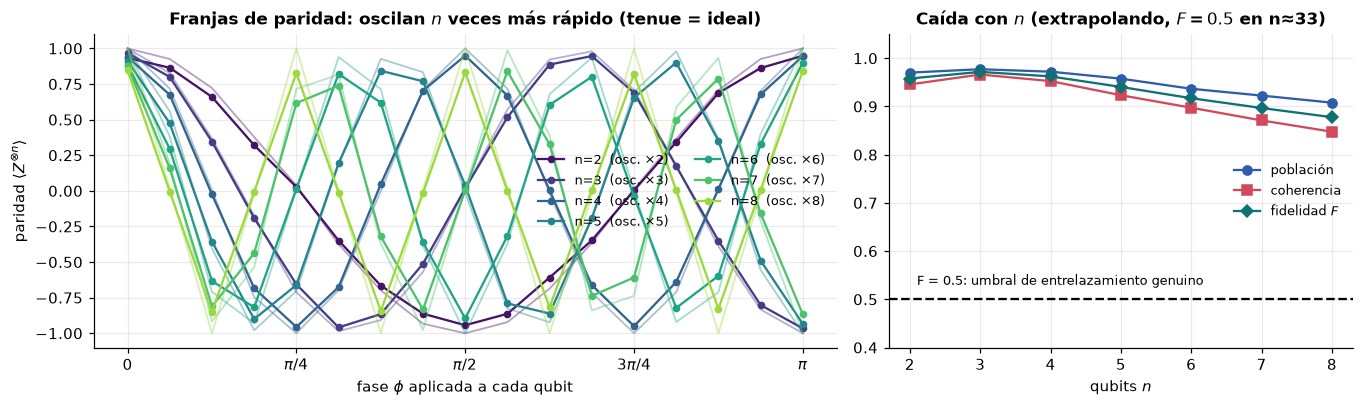

 n   población   coherencia   fidelidad GHZ
 2       0.970        0.946           0.958
 3       0.977        0.966           0.972
 4       0.972        0.953           0.962
 5       0.958        0.923           0.941
 6       0.937        0.897           0.917
 7       0.923        0.871           0.897
 8       0.908        0.848           0.878

caída de fidelidad por qubit agregado: -0.0156
extrapolando esa recta, F = 0.5 se cruzaría en n ≈ 33


In [16]:
def ghz_paridad(n: int, phi: float) -> QuantumCircuit:
    qc = ghz_arbol(n, medir=False)
    for q in range(n):
        qc.rz(phi, q)
    marca(qc, 3)
    for q in range(n):
        qc.h(q)
    marca(qc, 4)
    qc.add_register(ClassicalRegister(n, "c"))
    qc.measure(range(n), range(n))
    return qc


def paridad_de_counts(counts) -> float:
    total = sum(counts.values())
    return sum(v * (-1) ** k.count("1") for k, v in counts.items()) / total


fases = np.linspace(0, np.pi, 17)
NS_PAR = [2, 3, 4, 5, 6, 7, 8]
paridades_i, paridades_r, contrastes = {}, {}, {}
for n in NS_PAR:
    circs = [ghz_paridad(n, p) for p in fases]
    ci = utils.correr_ideal(circs, shots=2048)
    cr = utils.correr_ruidoso(circs, backend_falso=fez, shots=2048)
    paridades_i[n] = np.array([paridad_de_counts(c) for c in ci])
    paridades_r[n] = np.array([paridad_de_counts(c) for c in cr])
    contrastes[n] = (paridades_r[n].max() - paridades_r[n].min()) / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8),
                               gridspec_kw={"width_ratios": [1.6, 1]})
# n es una magnitud ordenada, así que va con un colormap secuencial y no con
# colores sueltos: el orden de las curvas se lee del color.
colores_n = plt.colormaps["viridis"](np.linspace(0.05, 0.85, len(NS_PAR)))
for i, n in enumerate(NS_PAR):
    ax1.plot(fases, paridades_i[n], "-", lw=1.2, color=colores_n[i], alpha=0.4)
    ax1.plot(fases, paridades_r[n], "o-", ms=4, color=colores_n[i],
             label=f"n={n}  (osc. ×{n})")
ax1.set_xlabel(r"fase $\phi$ aplicada a cada qubit")
ax1.set_ylabel(r"paridad $\langle Z^{\otimes n}\rangle$")
ax1.set_xticks(np.linspace(0, np.pi, 5))
ax1.set_xticklabels(["0", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$"])
ax1.set_title("Franjas de paridad: oscilan $n$ veces más rápido (tenue = ideal)")
ax1.legend(fontsize=8.5, ncol=2)

pob_par = [peso_ghz(counts_ghz_ruido[n], n) for n in NS_PAR]
coh_par = [contrastes[n] for n in NS_PAR]
fid_par = [(p + c) / 2 for p, c in zip(pob_par, coh_par)]
ax2.plot(NS_PAR, pob_par, "o-", ms=6, color=utils.COLOR_IDEAL, label="población")
ax2.plot(NS_PAR, coh_par, "s-", ms=6, color=utils.COLOR_RUIDO, label="coherencia")
ax2.plot(NS_PAR, fid_par, "D-", ms=6, color=utils.COLOR_HARD, label="fidelidad $F$")
ax2.axhline(0.5, color="k", lw=1.5, ls="--")
ax2.text(NS_PAR[0] + 0.1, 0.53, "F = 0.5: umbral de entrelazamiento genuino",
         fontsize=8.5)
# extrapolación lineal: ¿dónde cruzaría el umbral?
pend, orden = np.polyfit(NS_PAR, fid_par, 1)
n_umbral = (0.5 - orden) / pend
ax2.set_xlabel("qubits $n$")
ax2.set_ylabel("")
ax2.set_ylim(0.4, 1.05)
ax2.set_title(f"Caída con $n$ (extrapolando, $F=0.5$ en n≈{n_umbral:.0f})")
ax2.legend(fontsize=8.5)
utils.layout(fig)
plt.show()

print(f"{'n':>2}  {'población':>10}  {'coherencia':>11}  {'fidelidad GHZ':>14}")
for n, pob, coh, fid in zip(NS_PAR, pob_par, coh_par, fid_par):
    print(f"{n:>2}  {pob:>10.3f}  {coh:>11.3f}  {fid:>14.3f}")
print(f"\ncaída de fidelidad por qubit agregado: {pend:+.4f}")
print(f"extrapolando esa recta, F = 0.5 se cruzaría en n ≈ {n_umbral:.0f}")

**La fidelidad del estado GHZ se estima como**

$$F = \frac{P_{0\cdots0} + P_{1\cdots1}}{2} + \frac{C}{2},$$

con $C$ la amplitud de las franjas. Se necesitan las dos piezas: la
población
dice que los resultados están donde deben, y la coherencia dice que además
hay
superposición. Una $F > 0.5$ certifica entrelazamiento genuino de $n$
partes.

Miremos la tabla de cerca, porque el resultado es menos catastrófico de lo que
uno esperaría y eso también hay que decirlo. Entre $n=2$ y $n=8$ la
fidelidad
baja de $0.95$ a $0.88$: una pérdida de alrededor de **1.3 % por qubit
agregado**. GHZ de 8 qubits sigue **muy** por encima del umbral de 0.5. El
hardware NISQ de hoy hace esto sin transpirar, y por eso GHZ de 3 a 5 es una
demo confiable para dar en clase.

Lo que sí se nota es **cuál de los dos términos cae más rápido**. La
población
pasa de 0.971 a 0.902; la coherencia, de 0.936 a 0.850. La coherencia pierde
un poco más, y eso apunta al mecanismo dominante: el **desfasaje** por
encima de la relajación. Tiene sentido físico — en Heron $T_2$ es
típicamente menor que
$T_1$, así que la fase se degrada antes que la población.

La extrapolación de la recta dice dónde estaría el límite real de este
circuito en este chip. Tomala con pinzas: la caída no tiene por qué seguir
siendo lineal, y con más qubits el transpilador empieza a meter SWAPs que
aceleran todo. Pero da la escala correcta de qué se puede prometer.

---
# 5. Hardware real

Dos experimentos, cada uno con su flag. Recordemos el presupuesto: **10 minutos
de QPU por ventana de 28 días**, y que el overhead por job (~2.5 s) pesa más
que los shots en trabajos chicos. Por eso todo va en pocos jobs con muchos
circuitos.

In [17]:
if service is not None:
    print(f"{'backend':<16} {'qubits':>6} {'cola':>6}  {'estado':<10}")
    print("-" * 46)
    for b in service.backends(simulator=False):
        st = b.status()
        print(f"{b.name:<16} {b.num_qubits:>6} {st.pending_jobs:>6}  {st.status_msg:<10}")
else:
    print("sin autenticar")

sin autenticar


In [18]:
BACKEND_FIJO = None      # p.ej. "ibm_fez"; None = el menos ocupado

backend = None
if service is not None:
    backend = (service.backend(BACKEND_FIJO) if BACKEND_FIJO
               else service.least_busy(operational=True, simulator=False))
    st = backend.status()
    print(f"elegido: {backend.name}  ·  {st.status_msg}  ·  cola {st.pending_jobs}")
else:
    print("sin autenticar: no hay backend")

sin autenticar: no hay backend


In [19]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

SHOTS_HW = 4096
t_chsh = t_ghz = None

if backend is not None:
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    t_chsh = pm.run(chsh)
    circuitos_ghz_hw = ([ghz_arbol(n) for n in NS] +
                        [ghz_cadena(n) for n in NS] +
                        [ghz_paridad(4, p) for p in np.linspace(0, np.pi, 13)])
    t_ghz = pm.run(circuitos_ghz_hw)

    print("=== Experimento A: CHSH (4 circuitos) ===")
    costo_a = utils.informe_transpilacion(t_chsh, shots=SHOTS_HW,
                                          nombre_backend=backend.name)
    print("\n=== Experimento B: GHZ, escalado + paridad ===")
    costo_b = utils.informe_transpilacion(t_ghz, shots=SHOTS_HW,
                                          nombre_backend=backend.name)
    print(f"\ntotal si mandás los dos: ~{costo_a + costo_b:.1f} s de QPU")
else:
    print("sin backend: nada que transpilar")

sin backend: nada que transpilar


### Experimento A — CHSH en el chip

Cuatro circuitos de dos qubits, profundidad chica. Es el experimento con
mejor
relación señal/costo de todo el curso: esperá $S$ entre **2.2 y 2.6**.

Y el número importa por lo que *no* es. No es 2.83, porque el ruido degrada
la
correlación. Pero está lejos de 2, y **2 es un techo que ninguna teoría
realista local puede pasar, con ruido o sin ruido**. La brecha entre lo
medido
y 2.83 es ingeniería; la brecha entre lo medido y 2 es física.

In [20]:
ENVIAR_CHSH = False    # ponerlo en True para gastar QPU

if ENVIAR_CHSH:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_chsh, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"02 CHSH: 4 angulos, {SHOTS_HW} shots",
                        notebook="02", experimento="chsh",
                        n_circuitos=len(t_chsh), shots=SHOTS_HW,
                        combinaciones=[f"{a}{b}" for a, b, _ in COMBINACIONES])
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


### Experimento B — GHZ, el escalado completo

$2\times 7$ circuitos de GHZ (árbol y cadena, de 2 a 8 qubits) más 13 de
barrido de paridad con $n=4$: 27 circuitos en un solo job. Con esto sale, de
una corrida:

- la caída de población contra $n$,
- la comparación **árbol contra cadena** en hardware real,
- y la fidelidad GHZ con su parte coherente.

In [21]:
ENVIAR_GHZ = False     # ponerlo en True para gastar QPU

if ENVIAR_GHZ:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_ghz, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"02 GHZ: arbol y cadena n={NS} + paridad n=4, {SHOTS_HW} shots",
                        notebook="02", experimento="ghz",
                        n_circuitos=len(t_ghz), shots=SHOTS_HW, ns=NS,
                        orden="arbol[7], cadena[7], paridad_n4[13]")
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


---
# 6. Recuperar y analizar

Nunca esperar la cola en vivo: se manda, se guarda el `job_id`, se vuelve
después.

In [22]:
registros = utils.listar_jobs(filtro="02 ")

In [23]:
JOB_ID_CHSH = ""   # vacío = el último CHSH registrado

if not JOB_ID_CHSH:
    reg = utils.ultimo_job(experimento="chsh")
    JOB_ID_CHSH = reg["job_id"] if reg else ""
    if reg:
        print(f"último CHSH: {JOB_ID_CHSH}  ({reg['backend']}, {reg['fecha']})")

if JOB_ID_CHSH and service is not None:
    res = utils.recuperar(service, JOB_ID_CHSH).result()
    hw_chsh = [utils.counts_de_resultado(res, i) for i in range(len(res))]
    S_hw = valor_S(hw_chsh)
    print(f"\nS en hardware = {S_hw:.4f}")
    for (a, b, signo), c in zip(COMBINACIONES, hw_chsh):
        print(f"  {'-' if signo < 0 else '+'} E({a},{b}) = {correlacion(c):+.4f}")
else:
    hw_chsh, S_hw = None, None
    print("sin JOB_ID o sin autenticar: nada que recuperar")

sin JOB_ID o sin autenticar: nada que recuperar


In [24]:
if hw_chsh is not None:
    n_hw = sum(hw_chsh[0].values())
    err_S = 2 * np.sqrt(4 * (1 - (S_hw / 4) ** 2) / n_hw)   # cota grosera

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8),
                                   gridspec_kw={"width_ratios": [1, 1.2]})
    valores = [2 * np.sqrt(2), S_ideal, S_ruido, S_hw]
    etiquetas = ["teoría", "Aer ideal", "FakeFez", "hardware"]
    colores = [utils.COLOR_TEORIA, utils.COLOR_IDEAL, utils.COLOR_RUIDO,
               utils.COLOR_HARD]
    ax1.bar(range(4), valores, color=colores, width=0.62)
    ax1.axhline(2, color="k", lw=2)
    ax1.text(3.4, 2.04, "límite clásico", ha="right", fontsize=9)
    ax1.set_xticks(range(4)); ax1.set_xticklabels(etiquetas, fontsize=9)
    ax1.set_ylim(0, 3.3); ax1.set_ylabel("$S$")
    for i, v in enumerate(valores):
        ax1.text(i, v + 0.06, f"{v:.3f}", ha="center", fontweight="bold")
    ax1.set_title("CHSH: simulación y chip")

    x = np.arange(4)
    ax2.bar(x - 0.27, [np.cos(ANGULOS_CHSH[a] - ANGULOS_CHSH[b])
                       for a, b, _ in COMBINACIONES], 0.25,
            label="teoría", color=utils.COLOR_TEORIA)
    ax2.bar(x, [correlacion(c) for c in c_chsh_ideal], 0.25,
            label="Aer ideal", color=utils.COLOR_IDEAL)
    ax2.bar(x + 0.27, [correlacion(c) for c in hw_chsh], 0.25,
            label="hardware", color=utils.COLOR_HARD)
    ax2.set_xticks(x)
    ax2.set_xticklabels([f"E({a},{b})" for a, b, _ in COMBINACIONES], fontsize=9)
    ax2.axhline(0, color="0.5", lw=0.8)
    ax2.set_ylim(-1.05, 1.05)
    ax2.set_title("Las cuatro correlaciones, una por una")
    ax2.legend(fontsize=8.5)
    utils.layout(fig)
    plt.show()

    print(f"S = {S_hw:.4f} ± {err_S:.4f}")
    print(f"violación sobre el límite clásico: {(S_hw - 2) / err_S:.1f} sigmas")
    print(f"fracción del máximo cuántico alcanzada: {S_hw / (2 * np.sqrt(2)):.1%}")
else:
    print("(esta figura se llena cuando recuperes el job de CHSH)")

(esta figura se llena cuando recuperes el job de CHSH)


---
## Qué quedó establecido

1. **Superposición y entrelazamiento no son lo mismo.** Después de la $H$ el
   estado ya estaba en superposición y todavía factorizaba; el
     entrelazamiento
   aparece recién con la CNOT.
2. **El todo puede estar perfectamente determinado y las partes no.** Pureza
   global 1, pureza local 1/2, 1 bit de entropía de entrelazamiento — los
   discos punteados sin aguja.
3. **La correlación de Bell vale en toda base**, y eso ya no lo imita una
   moneda con papelitos.
4. **CHSH: $S \le 2$ para cualquier teoría realista local, y la mecánica
   cuántica da $2\sqrt2$.** El simulador lo confirma; el hardware da entre
     2.2
   y 2.6, que sigue estando del lado imposible.
5. **Escalando a GHZ de $n$ qubits**, la población se mantiene y la coherencia
se
   cae. El techo de NISQ no es un límite de tamaño: es un límite de *fase*.

**Siguiente:** `03_teleportacion_y_superdenso.ipynb` — qué se puede hacer
con
un par de Bell, en las dos direcciones.